# Adilet Search: a controlled research comparison

Research questions: do recent embeddings outperform E5, does hybrid reranking help, and does LLM query rewriting improve retrieval? Compare quality by language and discuss efficiency.

The existing title-derived labels are proxies. Body-only indexing removes direct title-header overlap but does not turn these queries into human-gold natural-language questions. A pilot is an implementation check, not a final scientific conclusion.

In [1]:
from pathlib import Path
import json
from IPython.display import display, Markdown
root = next(c for p in [Path.cwd(), *Path.cwd().parents] for c in (p, p / 'adilet-search', p / 'Group Project' / 'adilet-search') if (c / 'ml/experiments').exists())
full_path = root / 'ml/experiments/research-full/results.json'
final_path = root / 'ml/experiments/research-final/results.json'
result_path = final_path if final_path.exists() else (full_path if full_path.exists() else root / 'ml/experiments/research-pilot/results.json')
result = json.loads(result_path.read_text(encoding='utf-8'))
required = {'e5', 'current_hybrid_reranker', 'qwen3', 'bge_m3'}
assert required <= set(result['methods']), 'Comparison is incomplete; do not report a winner yet.'
print('Scope:', result['scope'])
print('Pilot per language per split:', result['pilot_per_language'])
print('Hardware:', result['device'])

Scope: Full frozen validation/test split; title-derived proxy labels; body-only corpus
Pilot per language per split: 0
Hardware: NVIDIA GeForce RTX 5060 Laptop GPU


## Methods and measurements
Checkpoint revisions are resolved and recorded in the run artifact. Same corpus, body-only chunks, 512-token budget, normalized cosine similarity and frozen splits. The hybrid control uses local BM25 and the project cross-encoder; Qdrant IDF differs.
E5/Qwen3/BGE-M3 use FP16; EmbeddingGemma 2 uses its supported BF16 text-only configuration. This compares practical configurations, not an isolated architecture effect.

In [2]:
methods = result['methods']
lines = ['| Method | Validation nDCG@10 | Test nDCG@10 | RU test | KK test |', '|---|---:|---:|---:|---:|']
for name, method in methods.items():
    s = method['splits']
    values = [s['val:all']['ndcg@10'], s['test:all']['ndcg@10'], s['test:ru']['ndcg@10'], s['test:kk']['ndcg@10']]
    lines.append('| '+name+' | '+' | '.join(f'{x:.3f}' for x in values)+' |')
display(Markdown('\n'.join(lines)))
print('Validation-selected candidate:', result['validation_winner'])

| Method | Validation nDCG@10 | Test nDCG@10 | RU test | KK test |
|---|---:|---:|---:|---:|
| e5 | 0.706 | 0.703 | 0.802 | 0.605 |
| current_hybrid_reranker | 0.856 | 0.846 | 0.855 | 0.836 |
| hybrid_no_reranker | 0.778 | 0.770 | 0.816 | 0.724 |
| qwen3 | 0.539 | 0.548 | 0.667 | 0.430 |
| bge_m3 | 0.830 | 0.822 | 0.833 | 0.812 |
| embeddinggemma2 | 0.710 | 0.716 | 0.802 | 0.630 |

Validation-selected candidate: current_hybrid_reranker


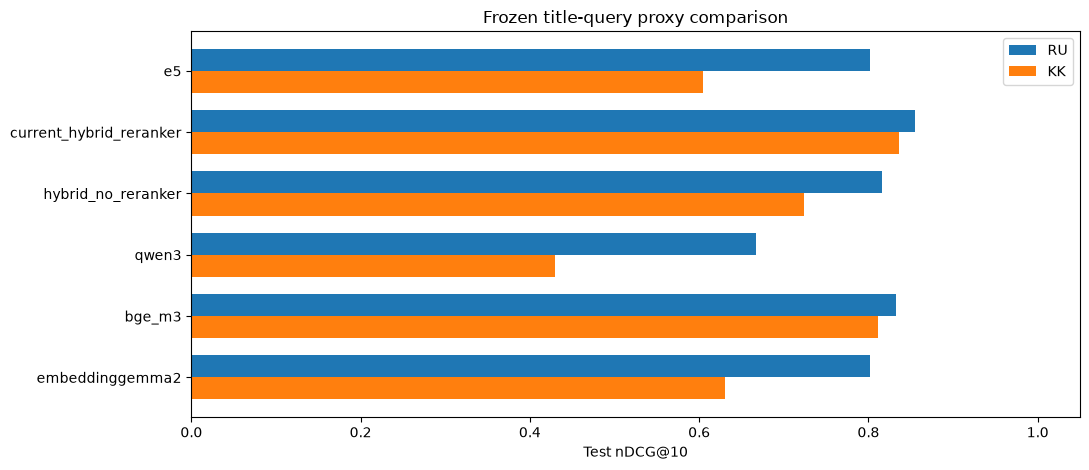

In [3]:
import matplotlib.pyplot as plt
import numpy as np
names = list(methods)
y = np.arange(len(names))
fig, ax = plt.subplots(figsize=(11, 4.8))
for offset, lang in [(-.18, 'ru'), (.18, 'kk')]:
    ax.barh(y+offset, [methods[name]['splits']['test:'+lang]['ndcg@10'] for name in names], height=.36, label=lang.upper())
ax.set(xlim=(0, 1.05), xlabel='Test nDCG@10', title='Frozen title-query proxy comparison')
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.legend(); fig.tight_layout()
fig.savefig(root / 'docs/report/research_quality.png', dpi=200, bbox_inches='tight')
plt.show()


## Uncertainty and interpretation
Use paired article-family bootstrap intervals so parallel RU/KK queries stay together. With a small pilot, intervals have little power. Do not infer general superiority from a single higher mean. API p95 and external LLM call latency require separate measurements.

In [4]:
for name, interval in result.get('paired_test_ndcg10_delta_vs_e5', {}).items():
    print(name, interval)
print('Next: evaluate independently human-reviewed plain-language RU/KK queries and test prompt/context sensitivity; see docs/report/RESEARCH_FINDINGS.md for failures.')

current_hybrid_reranker {'mean': 0.14230256667789576, 'ci95': [0.12298292793474712, 0.16183837333918427]}
hybrid_no_reranker {'mean': 0.06673478752747544, 'ci95': [0.05219937651325371, 0.08161939251810983]}
qwen3 {'mean': -0.15514902493908972, 'ci95': [-0.18022632626388593, -0.12909665442692933]}
bge_m3 {'mean': 0.1187737392677353, 'ci95': [0.1003754848036405, 0.13789351826014323]}
embeddinggemma2 {'mean': 0.01259535635305398, 'ci95': [-0.006168421605357658, 0.03132147859409432]}
Next: evaluate independently human-reviewed plain-language RU/KK queries and test prompt/context sensitivity; see docs/report/RESEARCH_FINDINGS.md for failures.


## Separate LLM-rewriting pilot
The LLM pilot has a smaller matched query cohort. Compare the treatment with E5 on that same cohort; do not compare its aggregate directly with the full experiment.

In [5]:
pilot = json.loads((root / 'ml/experiments/research-pilot/results.json').read_text(encoding='utf-8'))
for name in ['e5', 'e5_llm_rewrite']:
    print(name, pilot['methods'][name]['splits']['test:all'])

e5 {'queries': 8, 'ndcg@10': 0.7150232675709843, 'recall@10': 0.875, 'recall@50': 1.0, 'mrr@10': 0.6678571428571428}
e5_llm_rewrite {'queries': 8, 'ndcg@10': 0.6695258983885027, 'recall@10': 0.75, 'recall@50': 1.0, 'mrr@10': 0.6458333333333334}
